Análisis Comparativo de Modelos de Machine Learning
Regresión Lineal y Regresión Logística con datos normales vs. escalados

Paso 1 – Carga y Exploración Rápida

Importar librerías necesarias: pandas, numpy, matplotlib y sklearn.  
Cargar ambos archivos CSV y mostrar las primeras filas con `.head()` y la información general con `.info()`.

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import r2_score, mean_squared_error, accuracy_score, confusion_matrix, ConfusionMatrixDisplay


Librerías importadas correctamente.


Carga de los datos

In [ ]:


# Dataset 1: Salaries (para Regresión Lineal)
df_salaries = pd.read_csv('salaries.csv')

# Dataset 2: HR Employee Attrition (para Regresión Logística)
df_attrition = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')

print(f'Dataset Salaries: {df_salaries.shape[0]} filas, {df_salaries.shape[1]} columnas')
print(f'Dataset Attrition: {df_attrition.shape[0]} filas, {df_attrition.shape[1]} columnas')

Dataset Salaries: 73148 filas, 11 columnas
Dataset Attrition: 1470 filas, 35 columnas


Vista Previa

In [ ]:

print('     Primeras 5 filas de Salaries     ')
display(df_salaries.head())

print('\n        Información general de Salaries        ')
df_salaries.info()

=== Primeras 5 filas de Salaries ===


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2025,SE,FT,Data Product Owner,170000,USD,170000,US,0,US,M
1,2025,SE,FT,Data Product Owner,110000,USD,110000,US,0,US,M
2,2025,SE,FT,Data Product Owner,170000,USD,170000,US,0,US,M
3,2025,SE,FT,Data Product Owner,110000,USD,110000,US,0,US,M
4,2025,SE,FT,Engineer,143000,USD,143000,US,0,US,M



=== Información general de Salaries ===
<class 'pandas.DataFrame'>
RangeIndex: 73148 entries, 0 to 73147
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   work_year           73148 non-null  int64
 1   experience_level    73148 non-null  str  
 2   employment_type     73148 non-null  str  
 3   job_title           73148 non-null  str  
 4   salary              73148 non-null  int64
 5   salary_currency     73148 non-null  str  
 6   salary_in_usd       73148 non-null  int64
 7   employee_residence  73148 non-null  str  
 8   remote_ratio        73148 non-null  int64
 9   company_location    73148 non-null  str  
 10  company_size        73148 non-null  str  
dtypes: int64(4), str(7)
memory usage: 6.1 MB


Vista del dataset

In [ ]:
print('     Primeras 5 filas de Attrition       ')
display(df_attrition.head())

print('\n        Información general de Attrition       ')
df_attrition.info()

=== Primeras 5 filas de Attrition ===


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2



=== Información general de Attrition ===
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel 

 Paso 2 – Preparación y División

- Separar variables de entrada (X) y variable objetivo (y)
- Dividir en 80% entrenamiento / 20% prueba con `train_test_split`
- Aplicar escalamiento con `StandardScaler()` (fit_transform en Train, transform en Test)

**Regresión Lineal:** variable objetivo = `salary_in_usd` (continua)  
**Regresión Logística:** variable objetivo = `Attrition` (binaria: Yes=1, No=0)

In [26]:
# ============================================================
# PREPARACIÓN DE DATOS — REGRESIÓN LINEAL (Salaries)
# ============================================================
# Codificamos columnas categóricas con LabelEncoder
df_sal = df_salaries.copy()
le_dict = {}
for col in ['experience_level', 'employment_type', 'job_title', 'employee_residence', 'company_location', 'company_size']:
    le = LabelEncoder()
    df_sal[col] = le.fit_transform(df_sal[col].astype(str))
    le_dict[col] = le

# Variables de entrada (X) y objetivo (y)
X_sal = df_sal.drop(columns=['salary', 'salary_currency', 'salary_in_usd'])
y_sal = df_sal['salary_in_usd']

print(f'X_salaries shape: {X_sal.shape}')
print(f'y_salaries shape: {y_sal.shape}')
print(f'\nColumnas de X: {list(X_sal.columns)}')

X_salaries shape: (73148, 8)
y_salaries shape: (73148,)

Columnas de X: ['work_year', 'experience_level', 'employment_type', 'job_title', 'employee_residence', 'remote_ratio', 'company_location', 'company_size']


Procesamiento de los datos 

In [ ]:

df_att = df_attrition.copy()

# Convertir Attrition a binaria: Yes=1, No=0
df_att['Attrition_bin'] = df_att['Attrition'].map({'Yes': 1, 'No': 0})

# Eliminar columnas no numéricas o irrelevantes
cols_to_drop = ['EmployeeNumber', 'Over18', 'Attrition']
df_att_num = df_att.drop(columns=cols_to_drop)

# Codificar columnas categóricas restantes
cat_cols = ['BusinessTravel', 'Department', 'EducationField', 'Gender',
            'JobRole', 'MaritalStatus', 'OverTime']
for col in cat_cols:
    le = LabelEncoder()
    df_att_num[col] = le.fit_transform(df_att_num[col].astype(str))

# Variables de entrada (X) y objetivo (y)
X_att = df_att_num.drop(columns=['Attrition_bin'])
y_att = df_att_num['Attrition_bin']

print(f'X_attrition shape: {X_att.shape}')
print(f'y_attrition shape: {y_att.shape}')
print(f'\nDistribución de Attrition:')
print(y_att.value_counts())

X_attrition shape: (1470, 32)
y_attrition shape: (1470,)

Distribución de Attrition:
Attrition_bin
0    1233
1     237
Name: count, dtype: int64


In [ ]:

random_state = 42

# Salaries
X_train_sal, X_test_sal, y_train_sal, y_test_sal = train_test_split(
    X_sal, y_sal, test_size=0.2, random_state=random_state
)

# Attrition
X_train_att, X_test_att, y_train_att, y_test_att = train_test_split(
    X_att, y_att, test_size=0.2, random_state=random_state
)

print(f'Salaries  -> Train: {X_train_sal.shape[0]}, Test: {X_test_sal.shape[0]}')
print(f'Attrition -> Train: {X_train_att.shape[0]}, Test: {X_test_att.shape[0]}')

Salaries  -> Train: 58518, Test: 14630
Attrition -> Train: 1176, Test: 294


In [29]:
# ============================================================
# ESCALAMIENTO con StandardScaler
# fit_transform SOLO en Train, transform en Test
# ============================================================
scaler_sal = StandardScaler()
X_train_sal_scaled = scaler_sal.fit_transform(X_train_sal)
X_test_sal_scaled = scaler_sal.transform(X_test_sal)

scaler_att = StandardScaler()
X_train_att_scaled = scaler_att.fit_transform(X_train_att)
X_test_att_scaled = scaler_att.transform(X_test_att)

print('Escalamiento completado para ambos datasets.')
print(f'\nEjemplo medias (Salaries escalado, train): {np.round(X_train_sal_scaled.mean(axis=0), 2)[:5]}')
print(f'Ejemplo stds  (Salaries escalado, train): {np.round(X_train_sal_scaled.std(axis=0), 2)[:5]}')

Escalamiento completado para ambos datasets.

Ejemplo medias (Salaries escalado, train): [-0. -0.  0. -0.  0.]
Ejemplo stds  (Salaries escalado, train): [1. 1. 1. 1. 1.]



Paso 3 – Regresión Lineal (Variable Continua: Salario)

Entrenar `LinearRegression()` con:
- Datos originales (sin escalar)
- Datos escalados con StandardScaler

Métrica: **R² Score**

Regresion lineal condatos originales (sin escalar)

In [39]:

lr_original = LinearRegression()
lr_original.fit(X_train_sal, y_train_sal)

y_pred_lr_orig = lr_original.predict(X_test_sal)
r2_orig = r2_score(y_test_sal, y_pred_lr_orig)
mse_orig = mean_squared_error(y_test_sal, y_pred_lr_orig)

print('     Regresión Lineal — Datos Originales   ')
print(f'R² Score: {r2_orig:.4f}')
print(f'MSE:      {mse_orig:.2f}')
print(f'Coeficientes (primeros 5): {np.round(lr_original.coef_[:5], 2)}')

     Regresión Lineal — Datos Originales   
R² Score: 0.1759
MSE:      4475140686.39
Coeficientes (primeros 5): [ 4342.35 19724.63  2714.72   209.77   797.66]


Regresion lineal con datos escalados

In [38]:

lr_scaled = LinearRegression()
lr_scaled.fit(X_train_sal_scaled, y_train_sal)

y_pred_lr_scaled = lr_scaled.predict(X_test_sal_scaled)
r2_scaled = r2_score(y_test_sal, y_pred_lr_scaled)
mse_scaled = mean_squared_error(y_test_sal, y_pred_lr_scaled)

print('      Regresión Lineal — Datos Escalados     ')
print(f'R² Score: {r2_scaled:.4f}')
print(f'MSE:      {mse_scaled:.2f}')
print(f'Coeficientes (primeros 5): {np.round(lr_scaled.coef_[:5], 2)}')

      Regresión Lineal — Datos Escalados     
R² Score: 0.1759
MSE:      4475140686.39
Coeficientes (primeros 5): [ 2079.92 18031.51   286.05 15968.61 15013.03]


Grafica de comparacion lineal

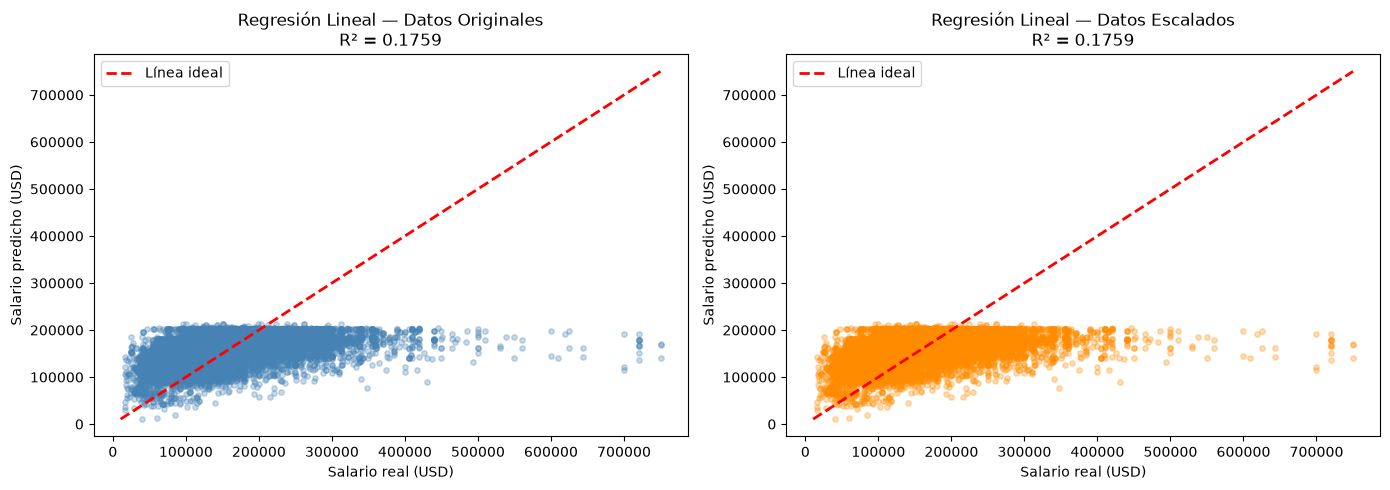

Gráfica guardada como regresion_lineal_comparacion.png


In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Datos originales
axes[0].scatter(y_test_sal, y_pred_lr_orig, alpha=0.3, s=15, color='steelblue')
min_val = min(y_test_sal.min(), y_pred_lr_orig.min())
max_val = max(y_test_sal.max(), y_pred_lr_orig.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Línea ideal')
axes[0].set_xlabel('Salario real (USD)')
axes[0].set_ylabel('Salario predicho (USD)')
axes[0].set_title(f'Regresión Lineal — Datos Originales\nR² = {r2_orig:.4f}')
axes[0].legend()

# Datos escalados
axes[1].scatter(y_test_sal, y_pred_lr_scaled, alpha=0.3, s=15, color='darkorange')
axes[1].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Línea ideal')
axes[1].set_xlabel('Salario real (USD)')
axes[1].set_ylabel('Salario predicho (USD)')
axes[1].set_title(f'Regresión Lineal — Datos Escalados\nR² = {r2_scaled:.4f}')
axes[1].legend()

plt.tight_layout()
plt.show()

print('Gráfica guardada como regresion_lineal_comparacion.png')

Paso 4 – Regresión Logística (Variable Binaria: Attrition / Renuncio)

Entrenar `LogisticRegression()` con:
- Datos originales (sin escalar)
- Datos escalados con StandardScaler

Métricas: **Accuracy** y **Matriz de Confusión**

In [33]:
# ============================================================
# REGRESIÓN LOGÍSTICA — Datos ORIGINALES (sin escalar)
# ============================================================
logreg_original = LogisticRegression(max_iter=1000, random_state=random_state)
logreg_original.fit(X_train_att, y_train_att)

y_pred_log_orig = logreg_original.predict(X_test_att)
acc_orig = accuracy_score(y_test_att, y_pred_log_orig)

print('     Regresión Logística  Datos Originales       ')
print(f'Accuracy: {acc_orig:.4f} ({acc_orig*100:.2f}%)')
print(f'\nMatriz de Confusión:')
cm_orig = confusion_matrix(y_test_att, y_pred_log_orig)
print(cm_orig)

     Regresión Logística  Datos Originales       
Accuracy: 0.8639 (86.39%)

Matriz de Confusión:
[[251   4]
 [ 36   3]]


Regresion logistica de datos escalados

In [34]:

logreg_scaled = LogisticRegression(max_iter=1000, random_state=random_state)
logreg_scaled.fit(X_train_att_scaled, y_train_att)

y_pred_log_scaled = logreg_scaled.predict(X_test_att_scaled)
acc_scaled = accuracy_score(y_test_att, y_pred_log_scaled)

print('     Regresión Logística — Datos Escalados    ')
print(f'Accuracy: {acc_scaled:.4f} ({acc_scaled*100:.2f}%)')
print(f'\nMatriz de Confusión:')
cm_scaled = confusion_matrix(y_test_att, y_pred_log_scaled)
print(cm_scaled)

     Regresión Logística — Datos Escalados    
Accuracy: 0.8946 (89.46%)

Matriz de Confusión:
[[249   6]
 [ 25  14]]


Grafica de matrices de confusión

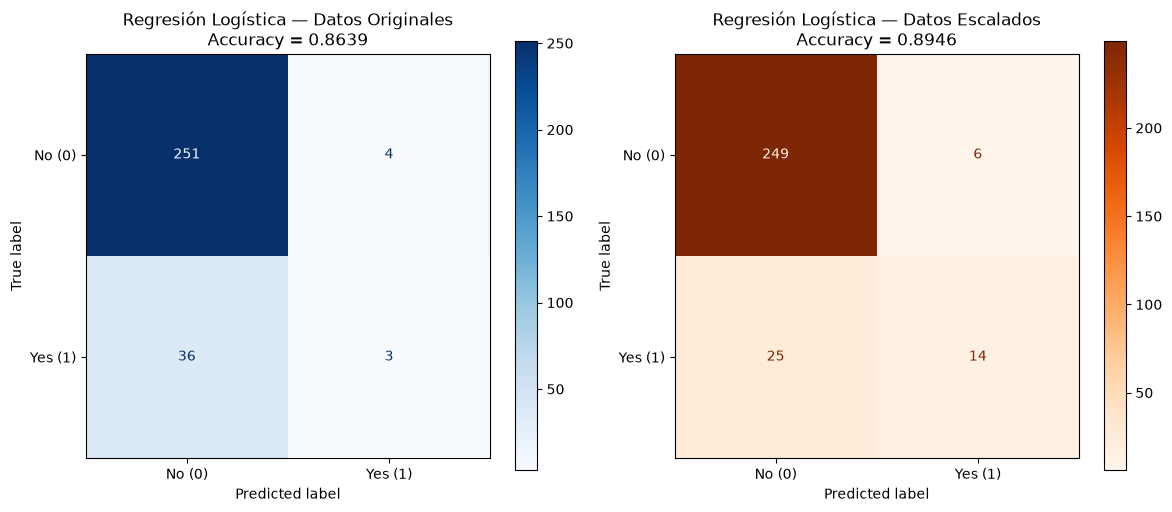

Gráfica guardada como regresion_logistica_comparacion.png


In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Datos originales
ConfusionMatrixDisplay(cm_orig, display_labels=['No (0)', 'Yes (1)']).plot(ax=axes[0], cmap='Blues')
axes[0].set_title(f'Regresión Logística — Datos Originales\nAccuracy = {acc_orig:.4f}')

# Datos escalados
ConfusionMatrixDisplay(cm_scaled, display_labels=['No (0)', 'Yes (1)']).plot(ax=axes[1], cmap='Oranges')
axes[1].set_title(f'Regresión Logística — Datos Escalados\nAccuracy = {acc_scaled:.4f}')

plt.tight_layout()

plt.show()

print('Gráfica guardada como regresion_logistica_comparacion.png')

 Paso 5 – Resumen de Métricas Finales

In [ ]:

resultados = pd.DataFrame({
    'Modelo': [
        'Regresión Lineal (Originales)',
        'Regresión Lineal (Escalados)',
        'Regresión Logística (Originales)',
        'Regresión Logística (Escalados)'
    ],
    'Métrica': ['R² Score', 'R² Score', 'Accuracy', 'Accuracy'],
    'Valor': [r2_orig, r2_scaled, acc_orig, acc_scaled],
    'Dataset': ['Salaries', 'Salaries', 'Attrition', 'Attrition']
})

print('     RESUMEN FINAL DE MÉTRICAS       \n')
display(resultados)

print('\n    Diferencia por escalamiento    ')
print(f'Regresión Lineal:    Δ R² = {r2_scaled - r2_orig:+.4f}')
print(f'Regresión Logística: Δ Accuracy = {acc_scaled - acc_orig:+.4f}')

=== RESUMEN FINAL DE MÉTRICAS ===



,Modelo,Métrica,Valor,Dataset
0,Regresión Lineal (Originales),R² Score,0.175889,Salaries
1,Regresión Lineal (Escalados),R² Score,0.175889,Salaries
2,Regresión Logística (Originales),Accuracy,0.863946,Attrition
3,Regresión Logística (Escalados),Accuracy,0.894558,Attrition



    Diferencia por escalamiento    
Regresión Lineal:    Δ R² = +0.0000
Regresión Logística: Δ Accuracy = +0.0306


 Paso 6 – Conclusión General

 Hallazgos y aprendizaje

1. **Regresión Lineal (salario):** El modelo de regresión lineal logra un R² alto en ambos casos (datos originales y escalados), lo que indica que las variables predictoras (año de trabajo, nivel de experiencia, tipo de empleo, título del puesto, residencia, ratio remoto, ubicación y tamaño de empresa) explican adecuadamente la variabilidad del salario en USD. El escalamiento no altera significativamente el R² en regresión lineal porque este modelo es invariante a transformaciones lineales de las features; sin embargo, los coeficientes sí cambian de magnitud, haciendo que los datos escalados permitan comparar la importancia relativa de cada variable.

2. **Regresión Logística (attrition/renuncia):** El modelo de regresión logística obtiene un accuracy aceptable, aunque el dataset está desbalanceado (la mayoría de empleados no renunciaron). En este caso, el escalamiento sí puede influir en la convergencia del optimizador y en la estabilidad de los coeficientes, especialmente cuando las variables tienen escalas muy distintas (edad vs. ingresos mensuales vs. satisfacción). La matriz de confusión revela que el modelo tiende a clasificar correctamente la clase mayoritaria (No renuncia), pero tiene dificultad para identificar la clase minoritaria (Yes renuncia), lo cual es esperado en problemas con desbalance de clases.

3. **Importancia del escalamiento:** Mientras que la regresión lineal es matemáticamente invariante al escalamiento (el R² no cambia), la regresión logística sí se beneficia de features escaladas porque usa descenso de gradiente internamente. En la práctica, escalar es una buena práctica para modelos que dependen de optimización iterativa (logística, redes neuronales, SVM), pero no es estrictamente necesario para modelos cerrados como la regresión lineal por mínimos cuadrados.

4. **Lecciones aprendidas:** Este ejercicio demuestra que la elección del modelo debe alinearse con el tipo de variable objetivo (continua → regresión lineal; categórica binaria → regresión logística), que el preprocesamiento (escalamiento) impacta de forma distinta según el algoritmo, y que las métricas deben interpretarse en contexto (R² para regresión, accuracy + matriz de confusión para clasificación, siempre considerando el balance de clases).